<a href="https://colab.research.google.com/github/Danusha6/AD325_Exercise/blob/main/FashionMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Image Classification with Dense Neural Networks

In [1]:
# Data Loading and Preprocessing
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

n = 42
np.random.seed(n)
tf.random.set_seed(n)

print("TensorFlow:", tf.__version__)
# Load MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
#Normalize
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape((x_train.shape[0], 28 * 28))
x_test = x_test.reshape((x_test.shape[0], 28 * 28))

class_names = ["Top", "Trouser", "Sweater", "Dress", "Coat", "Sandal","Shirt", "Sneaker", "Bag", "Ankle boot"]
print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)
print("Pixel range:", (float(x_train.min()), float(x_train.max())))

TensorFlow: 2.19.0
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train: (60000, 784)
y_train: (60000,)
x_test: (10000, 784)
y_test: (10000,)
Pixel range: (0.0, 1.0)


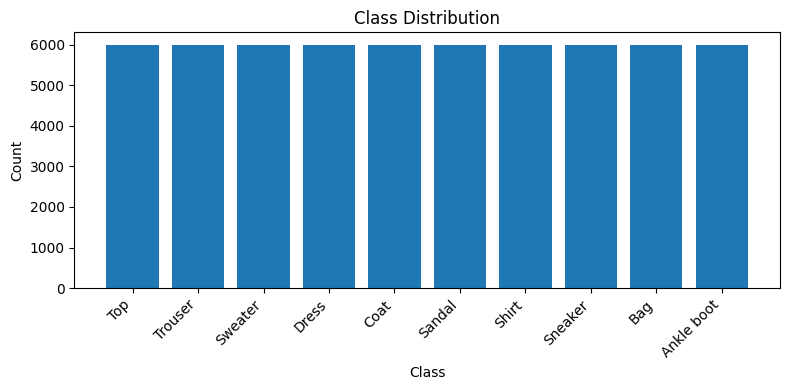

Class counts: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


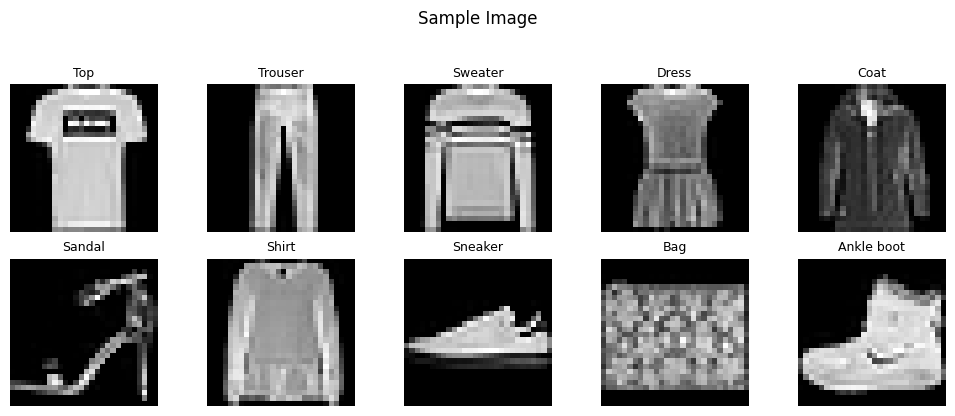

In [2]:
# Exploration and Visualization
# Class Distribution
counts = np.bincount(y_train, minlength = 10)

plt.figure(figsize=(8,4))
plt.bar(range(10), counts)
plt.xticks(range(10), class_names, rotation=45, ha='right')
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()
print("Class counts:", counts)

# Sample Image
(x_train_img, _), _ = keras.datasets.fashion_mnist.load_data()
example = []
for i in range(10):
  idx = np.where(y_train == i)[0][0]
  example.append(x_train_img[idx])

plt.figure(figsize=(10,4))
for i, img in enumerate(example):
  plt.subplot(2,5,i+1)
  plt.imshow(img, cmap='gray')
  plt.title(class_names[i], fontsize=9)
  plt.axis('off')
plt.suptitle("Sample Image", y=1.03)
plt.tight_layout()
plt.show()


In [3]:
# Model Implementation
from tensorflow.keras import models

# Shallow Template
def build_model_template_A(activation="relu"):
  model = models.Sequential([
      layers.Input(shape=(784,)),
      layers.Dense(128, activation=activation),
      layers.Dense(64, activation=activation),
      layers.Dense(10, activation="softmax")
  ])
  model.compile(
      optimizer="adam",
      loss="sparse_categorical_crossentropy",
      metrics=["accuracy"]
  )
  return model

# Deep Template
def build_model_template_B(activation="relu"):
  model = models.Sequential([
      layers.Input(shape=(784,)),
      layers.Dense(512, activation=activation),
      layers.Dense(256, activation=activation),
      layers.Dense(128, activation=activation),
      layers.Dense(64, activation=activation),
      layers.Dense(10, activation="softmax")
  ])
  model.compile(
      optimizer="adam",
      loss="sparse_categorical_crossentropy",
      metrics=["accuracy"]
  )
  return model
print("Templates successful")

Templates successful


In [ ]:
# Training 6 models
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

Activations = ["relu", "sigmoid", "tanh"]
Epochs = 5
Batch_Sizes = 128
Val_Split = 0.2

histories ={}
results = []

def plot_history(history, title):
  #Accuracy
  plt.figure(figsize=(7,4))
  plt.plot(history.history['accuracy'], label='Training Accuracy')
  plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
  plt.title(f"{title} - Accuracy")
  plt.xlabel('Epochs')
  plt.ylabel('Accuracy')
  plt.legend()
  plt.tight_layout()
  plt.show()

  #Loss
  plt.figure(figsize=(7,4))
  plt.plot(history.history['loss'], label='Training Loss')
  plt.plot(history.history['val_loss'], label='Validation Loss')
  plt.title(f"{title} - Loss")
  plt.xlabel('Epochs')
  plt.ylabel('Loss')
  plt.legend()
  plt.tight_layout()
  plt.show()
for arch_name, builder in [("Template_A", build_model_template_A),
                           ("Template_B", build_model_template_B)]:
  for act in Activations:
    model_key = f"{arch_name}_{act}"
    print(f"\n Training{model_key}")
    model = builder(activation=act)
    history = model.fit(
        x_train, y_train,
        batch_size=Batch_Sizes,
        epochs=Epochs,
        validation_split=Val_Split,
        verbose=0
    )
    histories[model_key] = history

    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    y_prob = model.predict(x_test, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    cm = confusion_matrix(y_test, y_pred)
    cr = classification_report(y_test, y_pred, target_names=class_names, digits=4)

    print(f"Test Accuracy: {test_acc:.4f}")
    print("Classification Report:\n", cr)

    results.append({
        "Model": model_key,
        "Test Loss": test_loss,
        "Test Accuracy": test_acc,
        "Confusion Matrix": cm
    })
    plot_history(history, title=model_key)
print("\n Finished Training all 6 models.")



 TrainingTemplate_A_relu


In [ ]:
# Evaluation and Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_results = pd.DataFrame([
    {"Model": r["Model"],
     "Test Accuracy": r["Test Accuracy"],
     "Test Loss": r["Test Loss"]
     }
    for r in results
]).sort_values(by="Test Accuracy", ascending=False).reset_index(drop=True)

print("Summary of Results:")
print(df_results)

best_row = df_results.iloc[0]
best_name = best_row["Model"]
best_cm = next(r["Confusion Matrix"] for r in results if r["Model"] == best_name)

print(f"\nBest Model: {best_name}")

plt.figure(figsize=(6,5))
plt.imshow(best_cm, interpolation='nearest')
plt.title(f"Confusion Matrix - {best_name}")
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.tight_layout()
plt.show()


### Performance of architecture and activations
The deep architecture or template B is slightly better than the shallow or template A. The deep learned more detialed patterns because it had more layers and neurons. In activation ReLU gave the best results for both templates. Sigmoid and Tanh worked but were slower and had lower accuracy. Overall, Template B with ReLU gave the highest accuracy.

### Evaluation metrics
The accuracy showed how often the model was overall but the classification report gave more detail. It showed precision, recall and F1-score for each class, which helped me see that some categories were harder to classify.

### Improvments
- Training more epochs.
- Trying data augentation or image preprocessing to give the model more variety.
- Adding batch normalization to reduce overfitting.

### Ethical Risk
The models can be biased if the training data isnot balanced it might lead to inaccurate results. There is also privacy risks if image contain personal data.